Starting the ML portion...

First model: Logistic Regression using broad labels ("B cell, T cell") and ~2000 genes

In [25]:
import scanpy as sc 
import pandas as pd
from sklearn.metrics import classification_report 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

adata = sc.read_h5ad("data/annotated_pbmc.h5ad")

In [11]:
X = adata.X
y = adata.obs["cell_type"]
X.shape

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=.2,
    random_state=42,
    stratify=y # assigns labels with the same proportion as the train  y
)

# create the model
model = LogisticRegression(
    max_iter=1000
)
# fit the model to X train and y train, it's learning now
model.fit(X_train, y_train)

# make prediction using X test
y_pred = model.predict(X_test)

# evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Model 1 Accuracy: {accuracy:.3f}")

print(adata.shape)
print(X.shape)
print(y.value_counts())
print(X_train.shape)
print(X_test.shape)
print(model.classes_)
print(accuracy_score(y_test, y_pred))

Model 1 Accuracy: 0.964
(2616, 1987)
(2616, 1987)
cell_type
T cell                     1075
Classical monocyte          509
B cell                      338
Memory/effector T cell      247
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                23
Megakaryocyte                 8
Name: count, dtype: int64
(2092, 1987)
(524, 1987)
['B cell' 'Classical monocyte' 'Dendritic/APC' 'FCGR3A+ monocyte'
 'Megakaryocyte' 'Memory/effector T cell' 'NK cell'
 'NK/cytotoxic lymphocyte' 'T cell']
0.9637404580152672


In [12]:
print(classification_report(y_test, y_pred))

                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.96      0.99      0.98       102
          Dendritic/APC       1.00      0.40      0.57         5
       FCGR3A+ monocyte       0.96      0.96      0.96        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.91      0.86      0.88        49
                NK cell       0.94      0.97      0.95        32
NK/cytotoxic lymphocyte       0.95      0.78      0.86        23
                 T cell       0.97      1.00      0.98       215

               accuracy                           0.96       524
              macro avg       0.97      0.88      0.91       524
           weighted avg       0.96      0.96      0.96       524



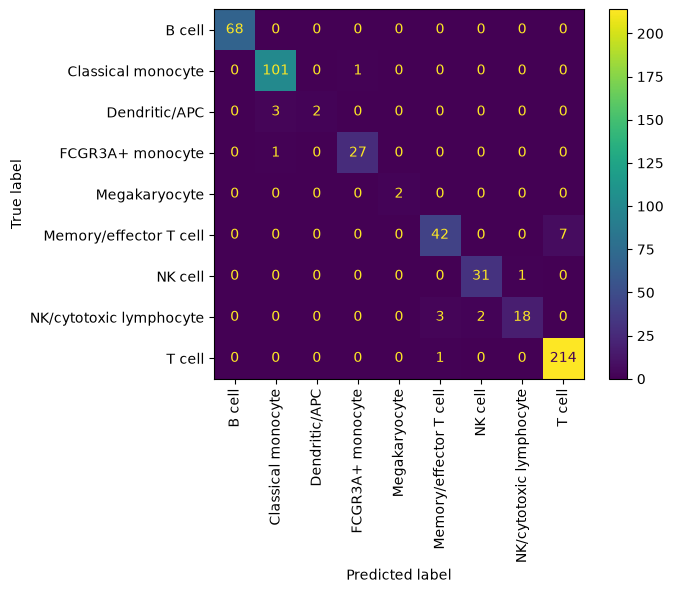

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=90)
plt.show()
# diagonal is the number of cells the model got correct
# off-diagonal shows what was misclassified

The model is confusing T/CD4 T cells with Naive T cells. This first model using 1987 gene features and 2092 cells is giving us 76% accuracy. What would it be if we used the 10 pca features instead? or if we did that with random forest or a pytorch neural network rather than logistic regression? 

Model 2: using 50 pcs to do log reg, meaning instead of using 2000 genes to draw a line of best fit, we use the pcs that capture the most variance instead. There is data leakage, because we found the pcs using test data too, so ignore these results and go to "fixing data leakage" section.

In [14]:
# the pc coordinates are stored here. each row is a cell, and each col is a feature (pc)
# the location of each cell in each pc direction represents their type of gene expression
adata.obsm["X_pca"].shape


(2616, 50)

In [15]:
X_pca10 = adata.obsm["X_pca"][:, :10]
X_pca10.shape

(2616, 10)

In [16]:
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca10, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

In [ ]:
model_pca10 = LogisticRegression(
    max_iter=1000
)
model_pca10.fit(X_train_pca, y_train_pca)

y_pred_pca10 = model_pca10.predict(X_test_pca)

accuracy_pca10 = accuracy_score(
    y_test_pca, y_pred_pca10
)
print(f"Model 2 - pca 10 Accuracy: {accuracy_pca10:.3f}")

PCA 10 accuracy: 0.987


Trying all 50 pcs now

In [18]:
X_pca50 = adata.obsm["X_pca"]
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca50, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

model_pca50 = LogisticRegression(
    max_iter=1000
)
model_pca50.fit(X_train_pca, y_train_pca)

y_pred_pca50 = model_pca50.predict(X_test_pca)

accuracy_pca50 = accuracy_score(
    y_test_pca, y_pred_pca50
)
print(f"PCA 50 accuracy: {accuracy_pca50:.3f}")
# the later pcs capture less variation and likely add noise

PCA 50 accuracy: 0.975


Fixing the data leakage: Logistic Regression using 10 pcs with proper split before finding pcs 

In [19]:
# start with original X and y
X = adata.X
y = adata.obs["cell_type"]

# split data before doing pca
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# truncatedSVD is for sparse matrices that gives us pca-like dim reduction
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

# svd is a model/object that can store the 50pcs and estimate
# train svd with train data then translate into new coordinate system 
X_train_pca = svd.fit_transform(X_train)
X_test_pca = svd.transform(X_test)
# you end up with X test and train in new coordinate system

# just take first 10 pcs
X_train_10 = X_train_pca[:, :10]
X_test_10 = X_test_pca[:, :10]

# train log reg
model_10 = LogisticRegression(max_iter=5000)

model_10.fit(X_train_10, y_train)

y_pred_10 = model_10.predict(X_test_10)

# evaluate
accuracy_10 = accuracy_score(y_test, y_pred_10)

print(f"10-component accuracy: {accuracy_10:.3f}")
print(classification_report(y_test, y_pred_10))

10-component accuracy: 0.990
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.98      1.00      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       1.00      0.96      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       1.00      0.98      0.99        49
                NK cell       0.94      1.00      0.97        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       1.00      1.00      1.00       215

               accuracy                           0.99       524
              macro avg       0.99      0.96      0.97       524
           weighted avg       0.99      0.99      0.99       524



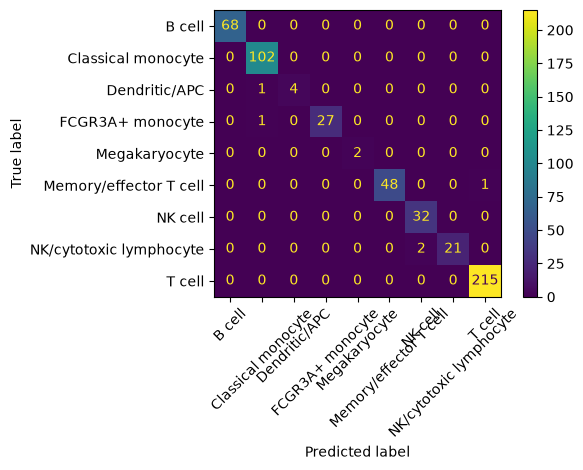

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_10,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

Saving the results of each model

In [29]:
model_results = {
    "Logistic regression": 0.99
}


Model 2 is Random Forest

In [24]:
# set up the model
rf_model = RandomForestClassifier(
    n_estimators=100, # 100 trees
    random_state=42
)

# train it 
rf_model.fit(
    X_train_10, y_train
)

# evaluate
y_pred_rf = rf_model.predict(X_test_10)

# calculate accuracy
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(f"Random Forest accuracy: {rf_accuracy:.3f}")
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest accuracy: 0.987
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.99      0.99      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       0.97      1.00      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.98      0.94      0.96        49
                NK cell       0.97      1.00      0.98        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       0.99      1.00      0.99       215

               accuracy                           0.99       524
              macro avg       0.99      0.96      0.97       524
           weighted avg       0.99      0.99      0.99       524



In [30]:
model_results["Random forest"] = 0.987
print(model_results)

{'Logistic regression': 0.99, 'Random forest': 0.987}


A more complicated model didn't improve accuracy, this dataset is linearly separable. RF, which is non linear, didn't add much.


In [26]:
# random forest has a concept, feature importances that tell you which pcs were most useful 
feature_importance = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(10)],
    "importance": rf_model.feature_importances_
})

feature_importance.sort_values(
    "importance",
    ascending=False
)

,PC,importance
2,PC3,0.240095
1,PC2,0.208087
3,PC4,0.206294
5,PC6,0.104662
4,PC5,0.100956
0,PC1,0.073817
7,PC8,0.030984
9,PC10,0.013070
8,PC9,0.011251
6,PC7,0.010784


PCs 2-4 contributed the most, almost 65% of the whole feature importance. Follow up question is, what genes make up these pcs? what genes are the most biologically indicative?

In [ ]:
svd.components_.shape

(50, 1987)

In [32]:
svd.components_[2]

array([ 0.02429347,  0.00013067, -0.00124702, ..., -0.00090125,
        0.01455521,  0.02909434], shape=(1987,), dtype=float32)

Making a df just for pc 3 to see which genes affect pc 3 most 

In [41]:
pc3_loadings = pd.DataFrame({
    "gene": adata.var_names,
    "loading": svd.components_[2]
})
pc3_loadings["abs_loading"] = pc3_loadings["loading"].abs()
pc3_loadings.sort_values("abs_loading", ascending=False).head(20)["gene"]

1877        NKG7
636          LTB
654     HLA-DPB1
1598        CCL5
1852       CD79A
646     HLA-DRB1
268         GNLY
653     HLA-DPA1
647     HLA-DQA1
1646       CD79B
546         GZMA
1715        CST7
1872        CD37
648     HLA-DQB1
1317        GZMB
1110        CTSW
1093       MS4A1
1010        PRF1
1007        SRGN
1368       TCL1A
Name: gene, dtype: object

SVD component 3 captures substantial variation in immune-cell expression programs, including cytotoxic lymphocyte, B-cell, and antigen-presentation signatures. Lets look at component 2 and 4:

In [45]:
def get_top_genes(component, n=20):
    loadings = pd.DataFrame({
        "gene": adata.var_names,
        "loading": svd.components_[component]
    })
    
    loadings["abs_loading"] = loadings["loading"].abs()
    
    return loadings.sort_values(
        "abs_loading",
        ascending=False
    ).head(n)

get_top_genes(1).head(20)["gene"]

1714       CST3
636         LTB
129      S100A8
1833     TYROBP
1459       IL32
1116    PTPRCAP
639        AIF1
637        LST1
965        FCN1
1939     LGALS1
158      FCER1G
1966       TYMP
1937     LGALS2
120        CTSS
1598       CCL5
813        SAT1
1877       NKG7
1535      COTL1
370        GPX1
1351       NPC2
Name: gene, dtype: object

Component 2 appears to capture variation associated with myeloid/monocyte identity.

In [46]:
get_top_genes(3).head(20)["gene"]

654     HLA-DPB1
1877        NKG7
653     HLA-DPA1
646     HLA-DRB1
537         IL7R
647     HLA-DQA1
1852       CD79A
1646       CD79B
1459        IL32
268         GNLY
636          LTB
648     HLA-DQB1
1317        GZMB
1715        CST7
1598        CCL5
546         GZMA
1093       MS4A1
1010        PRF1
466       FGFBP2
130       S100A6
Name: gene, dtype: object

So Component 4 appears to capture a broad lymphocyte/immune-state axis, distinguishing populations with different immune expression programs.

In [47]:
coef_df = pd.DataFrame(
    model_10.coef_,
    index=model_10.classes_,
    columns=[f"Component {i+1}" for i in range(10)]
)

coef_df

,Component 1,Component 2,Component 3,Component 4,Component 5,Component 6,Component 7,Component 8,Component 9,Component 10
B cell,-0.004582,0.058847,-2.248626,0.433672,-0.420242,-0.673275,-0.163391,-0.039930,-0.267722,0.154050
Classical monocyte,0.539508,1.342346,-0.115198,0.035113,0.825038,-0.496246,-0.230115,0.268923,-0.318816,0.166893
Dendritic/APC,0.536477,0.238624,-1.122619,0.382291,-0.202129,-0.726420,0.086457,-1.102250,-0.509530,0.228044
FCGR3A+ monocyte,-0.197152,1.001349,0.141375,-0.363525,-1.302280,0.364650,-0.325333,1.519508,-0.066692,0.103322
Megakaryocyte,0.026084,0.227283,0.090267,-0.028130,-0.170603,0.110400,0.553229,0.199275,0.214781,0.022970
Memory/effector T cell,-0.429876,-0.691688,0.722954,-0.578998,1.171574,1.696385,-0.287800,0.271996,0.441614,0.176174
NK cell,0.355256,-0.447845,1.957420,0.888042,-0.185150,-0.948817,0.506510,0.289778,0.648174,-0.031844
NK/cytotoxic lymphocyte,-0.699752,-1.676053,1.482862,0.801879,0.673402,0.755050,-0.233628,-0.648317,0.170711,-0.899072
T cell,-0.125805,-0.052909,-0.908447,-1.570351,-0.389607,-0.081736,0.094070,-0.758980,-0.312518,0.079461
